# 03a · Make tissue masks and tiles

Can I cut the same physical area out of slides from all five hospitals? I’ll use the ten slides from notebook 02b. A tissue mask marks the stained parts of each slide. A tile is a small square cut from one of those parts. The tile coordinates let me put every square back in its place on the original slide.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import sys

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import Image as DisplayImage, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "manifests/inspection_slides.csv").is_file())
sys.path.insert(0, str(ROOT / "src"))
from fetch_camelyon17_sample import load_inspection_manifest
from tile_camelyon17 import extract_slide, MASK_MPP, MIN_TISSUE, TARGET_MPP, TILE_PX

RAW = ROOT / "data/raw/camelyon17"
OUT = ROOT / "data/derived/camelyon17/tiling_pilot"
ARCHIVES = OUT / "slides"
rows = load_inspection_manifest()
for row in rows:
    files = [RAW / "images" / row["slide_id"]]
    if row["annotation_key"]:
        files.append(RAW / "annotations" / Path(row["annotation_key"]).name)
    for path in files:
        if not path.is_file():
            raise FileNotFoundError(f"{path.name} is missing. Run notebook 02b to fetch the inspection set.")
print(f"{len(rows)} local slides. Each {TILE_PX}-pixel tile spans {TILE_PX * TARGET_MPP:g} µm per side.")

10 local slides. Each 256-pixel tile spans 128 µm per side.


## Mark the tissue and cut the tiles

Black borders and pale glass both take up space in these scans. I look for pink or purple stain on an overview at about 8 µm per pixel. On the 0 to 255 RGB scale, the brightest channel must reach 40, the spread between channels must reach 15, and both red and blue must exceed green by at least 3. A 3 by 3 median filter removes isolated specks. These are starting values for this sample. Pale tissue and colored marks deserve a closer look in the previews.

I lay a grid over the whole slide, starting at the top left. A square stays if it fits completely inside the image and at least half its overview pixels pass the mask. At the mask scale, a tile is about 16 pixels wide. The tissue fraction is an estimate at that resolution.

A 256-pixel tile at 0.5 µm per pixel spans 128 µm. In the hospital 4 examples, that takes 512 original pixels. The code works out the width and height from each slide’s own calibration, reads a nearby pyramid level, and resizes the crop to 256 by 256. The saved box uses original slide coordinates. Its right and bottom edges are exclusive.

For each slide, this cell writes one ZIP under `data/derived/camelyon17/tiling_pilot/slides/`. It contains the JPEG tiles, their coordinates in `tiles.csv`, the binary mask, and the images for the visual check. Rerunning the cell rebuilds the archives from the local TIFFs.

In [2]:
summaries = []
for row in rows:
    result = extract_slide(row, RAW, ARCHIVES)
    summaries.append(result)
    print(f"{result['slide_id']}   {result['tiles']:,} tiles   {result['seconds']:.1f} seconds")

patient_019_node_4.tif   663 tiles   3.0 seconds


patient_012_node_0.tif   1,848 tiles   6.8 seconds


patient_031_node_4.tif   586 tiles   2.8 seconds


patient_034_node_3.tif   3,147 tiles   12.0 seconds


patient_053_node_4.tif   1,360 tiles   5.7 seconds


patient_044_node_4.tif   2,667 tiles   10.0 seconds


patient_065_node_2.tif   1,364 tiles   5.9 seconds


patient_075_node_4.tif   6,009 tiles   23.1 seconds


patient_083_node_4.tif   2,627 tiles   3.6 seconds


patient_092_node_1.tif   7,450 tiles   10.3 seconds


## Count what was kept

“Grid boxes” counts all complete squares before applying the mask. The JPEG size is the compressed size of the saved tiles. In the five slides with XML, I also check which tiles have their center inside a published tumor outline, after accounting for any exclusion polygons. A center inside an outline says where that tile is. A tile can straddle the outline. I apply this check after choosing the tiles, so tumor annotations never determine where to sample.

In [3]:
summary = pd.DataFrame(summaries)
summary.to_csv(OUT / "slide_summary.csv", index=False)
tables = []
for result in summaries:
    archive = ARCHIVES / (Path(result["slide_id"]).stem + ".zip")
    with ZipFile(archive) as bundle, bundle.open("tiles.csv") as stream:
        table = pd.read_csv(stream, dtype={"center_in_tumor": "boolean"})
    table.insert(0, "slide_id", result["slide_id"])
    tables.append(table)
coordinates = pd.concat(tables, ignore_index=True)
coordinates.to_csv(OUT / "tile_coordinates.csv", index=False)
counts = summary[["hospital", "label", "slide_id", "full_grid_boxes", "tiles", "centers_in_tumor"]].copy()
counts["centers_in_tumor"] = counts["centers_in_tumor"].astype("Int64")
counts["JPEG_MB"] = (summary.jpeg_bytes / 1e6).round(1)
display(counts)

,hospital,label,slide_id,full_grid_boxes,tiles,centers_in_tumor,JPEG_MB
0,0,negative,patient_019_node_4.tif,68442,663,<NA>,20.1
1,0,macro,patient_012_node_0.tif,68442,1848,718,57.5
2,1,negative,patient_031_node_4.tif,71820,586,<NA>,18.2
3,1,macro,patient_034_node_3.tif,71820,3147,174,96.2
4,2,negative,patient_053_node_4.tif,6969,1360,<NA>,43.5
5,2,macro,patient_044_node_4.tif,15352,2667,133,96.2
6,3,negative,patient_065_node_2.tif,71820,1364,<NA>,44.9
7,3,macro,patient_075_node_4.tif,68442,6009,744,190.6
8,4,negative,patient_083_node_4.tif,26918,2627,<NA>,88.5
9,4,macro,patient_092_node_1.tif,65880,7450,354,222.4


## Look at all ten slides

The second column tints the selected tissue green. The yellow box on the overview locates the detail in the third column. Teal lines mark retained tiles there, orange lines trace the published tumor outlines, and the yellow frame identifies the saved JPEG on the right. For the annotated examples, I look for a tile whose center is inside a tumor outline and whose entire box is clear of every tumor and exclusion boundary. When one is available, the saved tile on the right sits completely inside the outline. This choice affects the illustration alone.

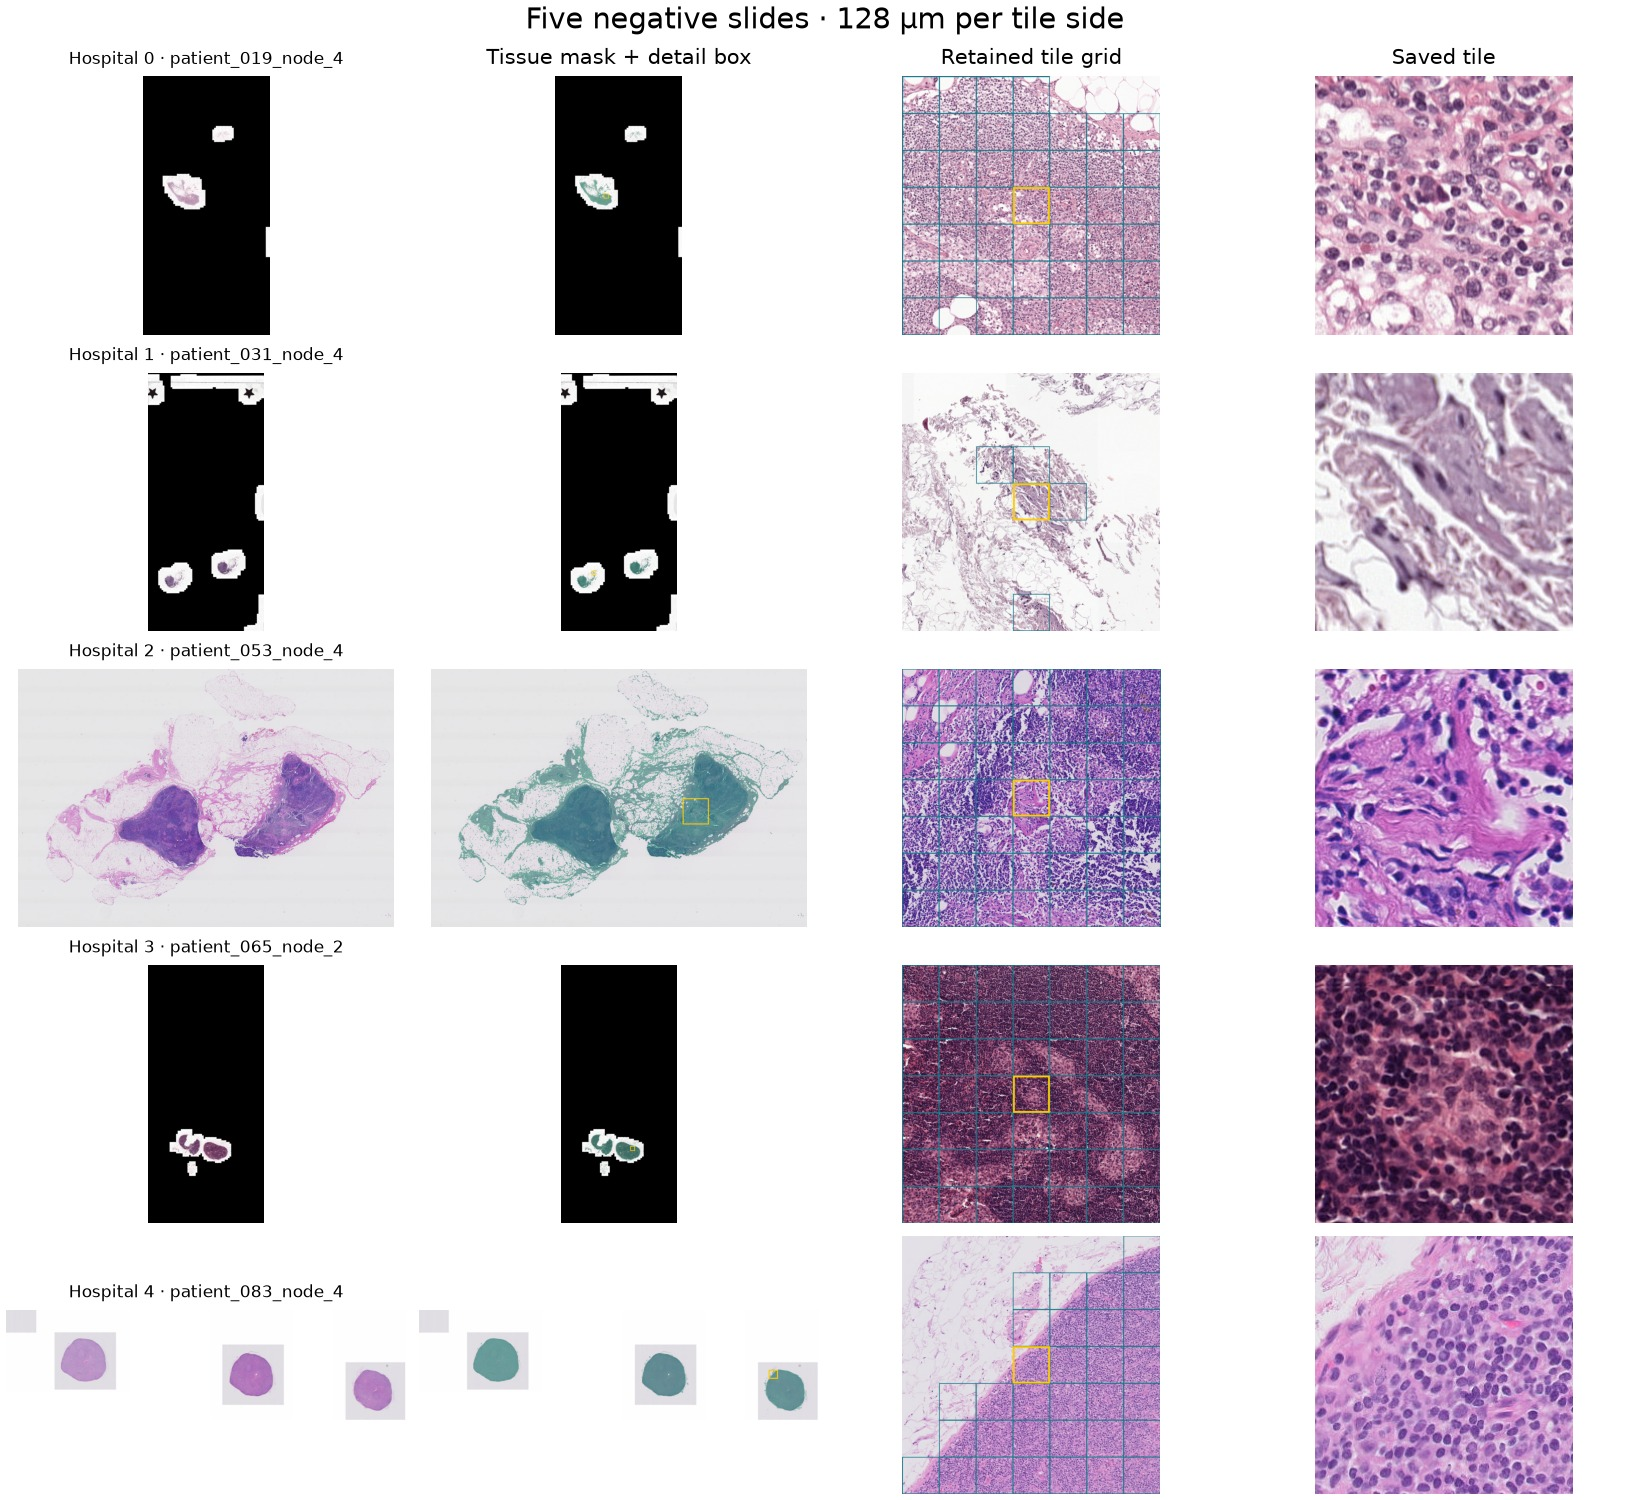

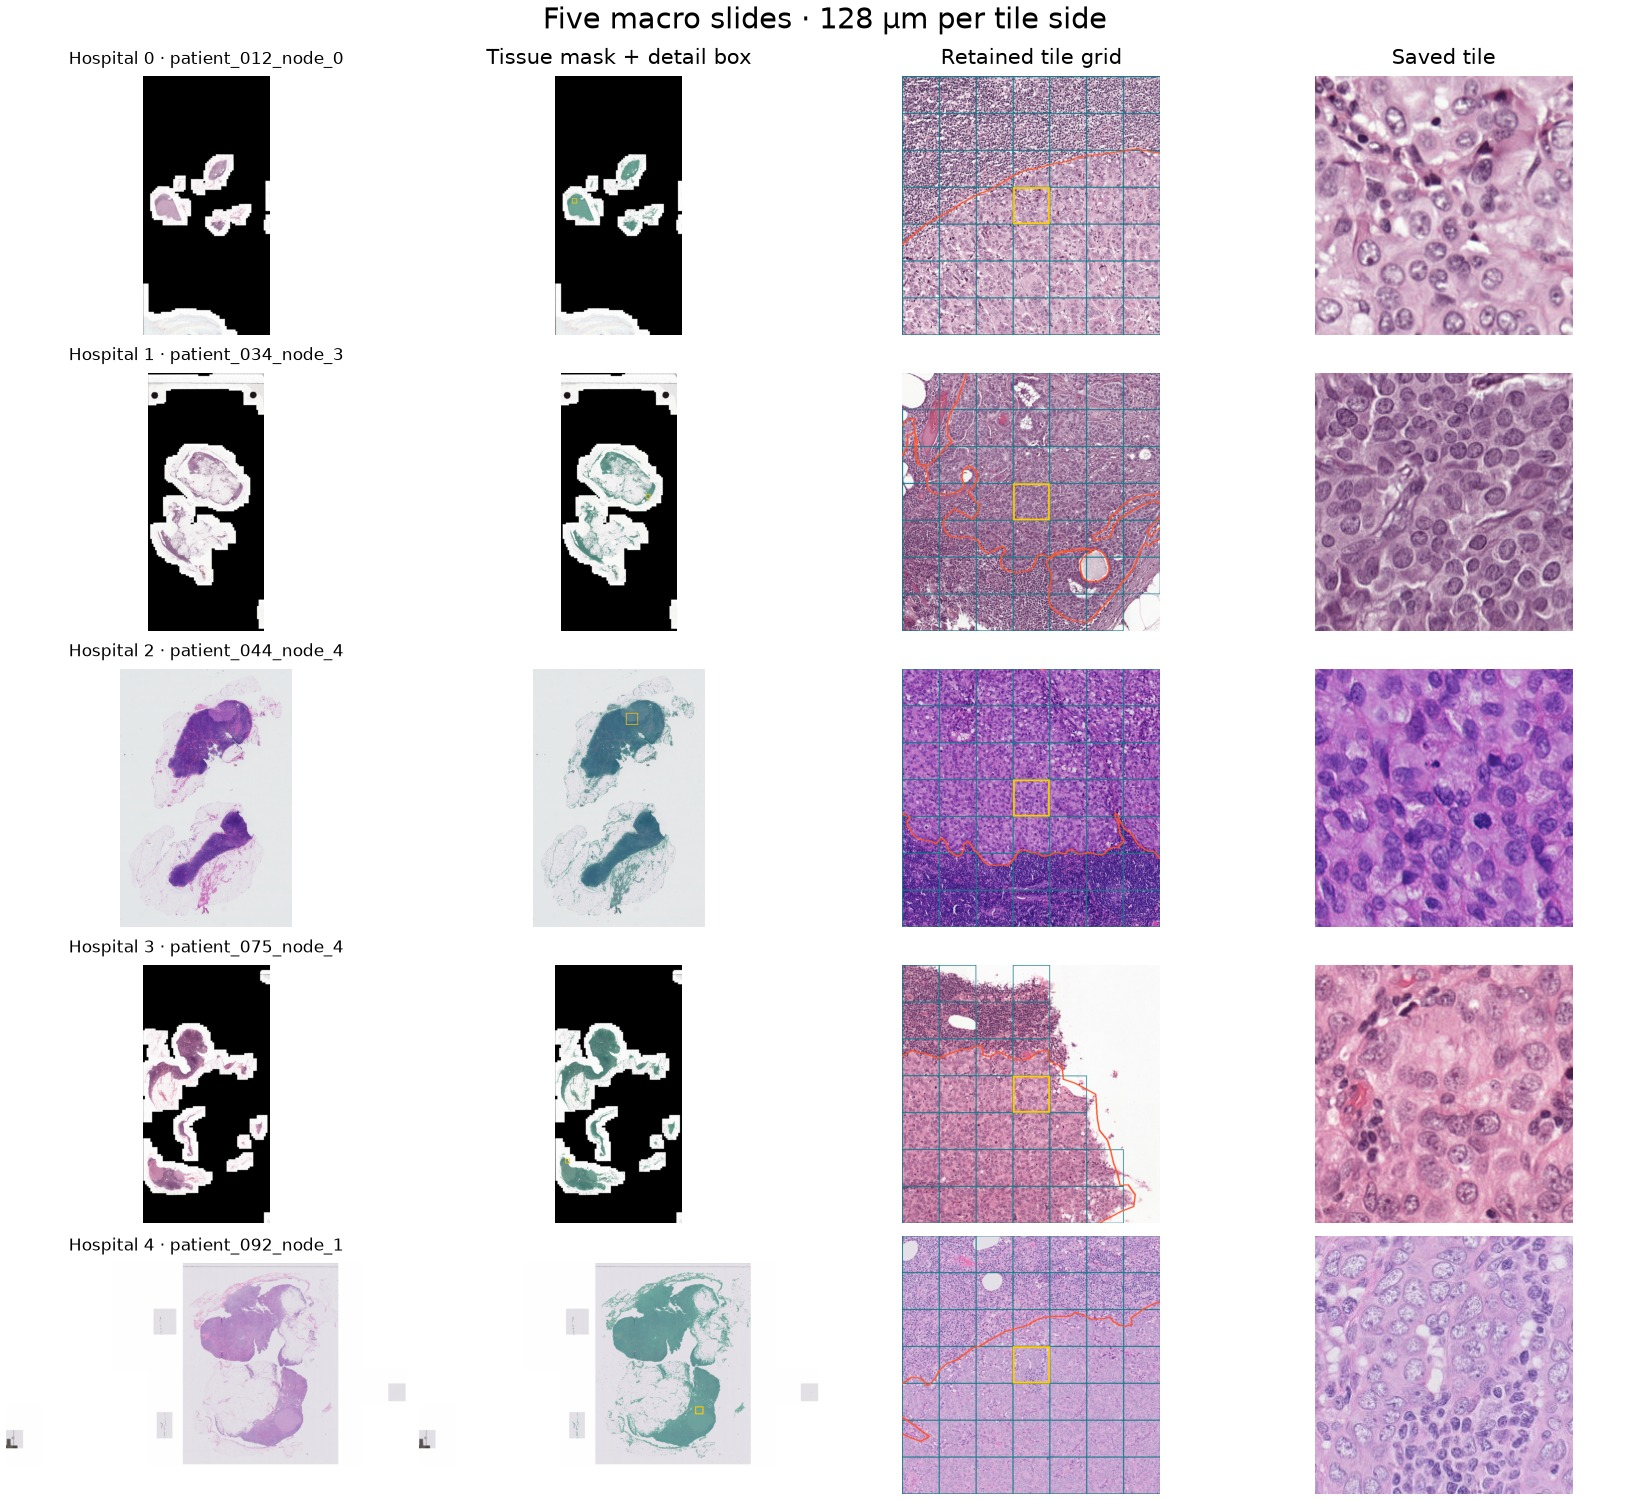

In [4]:
def archived_image(bundle, name):
    with bundle.open(name) as stream, Image.open(stream) as picture:
        return picture.copy()

for label in ("negative", "macro"):
    fig, axes = plt.subplots(5, 4, figsize=(11, 10), layout="constrained")
    for result in (row for row in summaries if row["label"] == label):
        axes_row = axes[result["hospital"]]
        archive = ARCHIVES / (Path(result["slide_id"]).stem + ".zip")
        with ZipFile(archive) as bundle:
            overview = archived_image(bundle, "overview.png")
            mask = archived_image(bundle, "mask.png").resize(overview.size, Image.Resampling.NEAREST)
            detail = archived_image(bundle, "grid_detail.png")
            example = archived_image(bundle, result["example_file"])
        tint = Image.blend(overview, Image.new("RGB", overview.size, "#10A36A"), 0.48)
        overlay = Image.composite(tint, overview, mask)
        x0, y0, x1, y1 = result["detail_box"]
        sx, sy = overview.width / result["width"], overview.height / result["height"]
        ImageDraw.Draw(overlay).rectangle((x0*sx, y0*sy, x1*sx, y1*sy), outline="#FFCC00", width=3)
        for ax, image in zip(axes_row, (overview, overlay, detail, example)):
            ax.imshow(image)
            ax.set_axis_off()
        stem = Path(result["slide_id"]).stem
        axes_row[0].set_title(f"Hospital {result['hospital']} · {stem}", fontsize=8)
    for ax, title in zip(axes[0, 1:], ("Tissue mask + detail box", "Retained tile grid", "Saved tile")):
        ax.set_title(title, fontsize=10)
    fig.suptitle(f"Five {label} slides · 128 µm per tile side", fontsize=14)
    path = OUT / f"qc_{label}.jpg"
    fig.savefig(path, dpi=150, pil_kwargs={"quality": 92})
    plt.close(fig)
    display(DisplayImage(filename=str(path), width=950))

## What would the full set cost to tile?

The pilot deliberately uses small TIFFs. I scale the time and JPEG storage by the ratio of compressed TIFF bytes in the 500 labeled slides to those in the pilot. The timing covers this Mac reading the local slides and making the tiles and inspection images. The estimate depends on how much tissue each file contains and how well it compresses.

In [5]:
labels = pd.read_csv(RAW / "stages.csv")["patient"]
image_keys = "CAMELYON17/images/" + labels[labels.str.endswith(".tif")]
inventory = pd.read_csv(RAW / "objects.csv").set_index("key")
cohort_bytes = int(inventory.loc[image_keys, "size_bytes"].sum())
factor = cohort_bytes / summary.image_bytes.sum()
print(f"Ten slides: {int(summary.tiles.sum()):,} tiles, {summary.jpeg_bytes.sum()/1e9:.3f} GB of JPEGs, "
      f"{summary.seconds.sum()/60:.1f} minutes.")
print(f"TIFF byte ratio for the {len(image_keys)} labeled slides: {factor:.1f}.")
print(f"Rough estimate on this Mac: {factor * summary.jpeg_bytes.sum()/1e9:.1f} GB of JPEGs and "
      f"{factor * summary.seconds.sum()/3600:.1f} hours for masking and tiling.")

Ten slides: 27,721 tiles, 0.878 GB of JPEGs, 1.4 minutes.
TIFF byte ratio for the 500 labeled slides: 87.2.
Rough estimate on this Mac: 76.6 GB of JPEGs and 2.0 hours for masking and tiling.


## What I learned from the pilot

All ten slides produced tiles. The count ranged from 586 on the hospital 1 negative slide to 7,450 on the hospital 4 macro slide. The 27,721 saved squares cover 127.87 to 128.11 µm per side after rounding to whole source pixels.

The large black borders and pale glass mostly stayed outside the mask in these examples. In the hospital 1 negative close-up, some pale strands sit between the retained boxes. The 50% cutoff favors denser stained tissue there. Across the five annotated slides, 2,123 retained tile centers fall inside a tumor outline. The center count includes squares that can cross a boundary. The right-hand tile in each annotated example also passed a whole-square containment check.

The next part of step 3 uses the saved JPEGs and their coordinates to check feature extraction with frozen ResNet-50.

## Sources

The slide selection and published annotation files come from [CAMELYON on AWS](https://registry.opendata.aws/camelyon/). OpenSlide defines the coordinate convention for reading regions and the two physical pixel-size properties. [OpenSlide Python API](https://openslide.org/api/python/#openslide.OpenSlide.read_region)

The Histolab workflow informed the checks on mask resolution, stored coordinates, and using the same mask for preview and extraction. The implementation here uses the project’s existing OpenSlide, NumPy and Pillow environment. Kassis, Agarwal, He, Patel and Brueckner (2026), [Scientific Agent Skills](https://doi.org/10.48550/arXiv.2609.00065).